# 05 — Avaliação de métricas e conclusões do baseline

**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Este notebook reúne a avaliação por classe e as métricas oficiais do baseline, além das conclusões e dificuldades.

São avaliadas duas condições:
- **Baseline (referência):** modelo treinado sem data augmentation.
- **Baseline + augmentation:** modelo treinado com data augmentation.

A avaliação utiliza o conjunto de teste e os modelos salvos pelo notebook 03.

## 1. Preparação do ambiente e carregamento dos dados

Esta célula executa o notebook 01 para reconstruir o conjunto de teste e obter os nomes e a ordem das classes. Assim, este notebook pode ser executado separadamente, desde que as dependências do projeto estejam instaladas.

In [1]:
from pathlib import Path
from IPython import get_ipython
from IPython.utils.capture import capture_output

notebook_dir = Path.cwd()
if (notebook_dir / 'notebooks').is_dir():
    notebook_dir = notebook_dir / 'notebooks'

notebook_01 = notebook_dir / '01_data_ingestion_preprocessing.ipynb'
assert notebook_01.exists(), (
    f'Não encontrei {notebook_01}. Abra este notebook a partir da pasta do projeto '
    'ou ajuste o caminho de notebook_01.'
)

with capture_output() as run_01_output:
    get_ipython().run_line_magic('run', f'"{notebook_01}"')

print('Classes:', labels)
print('Imagens no conjunto de teste:', len(dataset['test']))

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
Imagens no conjunto de teste: 128


## 2. Carregamento dos modelos baseline

Os modelos precisam ter sido salvos anteriormente pela seção 8 do notebook 03, na pasta `data/processed/`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

ARTIFACTS_DIR = output_dir

model_paths = {
    'baseline': ARTIFACTS_DIR / 'baseline.keras',
    'baseline_aug': ARTIFACTS_DIR / 'baseline_aug.keras',
}

missing_models = [str(path) for path in model_paths.values() if not path.exists()]
assert not missing_models, (
    'Não encontrei os modelos salvos. Execute primeiro o notebook 03 até a seção 8. '
    'Arquivos ausentes: ' + ', '.join(missing_models)
)

models = {
    'baseline': keras.models.load_model(model_paths['baseline']),
    'baseline_aug': keras.models.load_model(model_paths['baseline_aug']),
}

condition_names = {
    'baseline': 'Baseline (referência)',
    'baseline_aug': 'Baseline + augmentation',
}

print('Modelos carregados com sucesso.')

Modelos carregados com sucesso.


## 3. Avaliação por classe e métricas oficiais

Além da acurácia geral, esta etapa avalia as duas condições utilizando as três métricas definidas para o desafio: Acurácia Global, F1-Score Macro e Matriz de Confusão.

A avaliação é realizada sobre o conjunto de teste, que não foi utilizado durante o treinamento nem na escolha dos pesos do modelo.

A análise por classe permite identificar quais doenças são classificadas corretamente com maior frequência e quais apresentam maior dificuldade de identificação.

In [3]:
y_true = np.array(dataset['test']['labels'])
predictions = {}
results = {}

for key, model in models.items():
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    predictions[key] = y_pred

    accuracy = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro')
    results[key] = {
        'accuracy': float(accuracy),
        'f1_macro': float(f1_macro),
    }

    print(f"===== {condition_names[key]} =====")
    print(f"Acurácia Global: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"F1-Score Macro: {f1_macro:.4f}")
    print("\nRelatório por classe:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=labels,
        digits=4,
        zero_division=0,
    ))

import json

official_metrics = {
    'labels': list(labels),
    'results': results,
    'classification_reports': {
        key: classification_report(
            y_true,
            predictions[key],
            target_names=labels,
            digits=4,
            zero_division=0,
            output_dict=True,
        )
        for key in predictions
    },
    'confusion_matrices': {
        key: confusion_matrix(y_true, predictions[key]).tolist()
        for key in predictions
    },
}
metrics_path = ARTIFACTS_DIR / 'baseline_official_metrics.json'
metrics_path.write_text(json.dumps(official_metrics, indent=2), encoding='utf-8')
print(f'Métricas oficiais salvas em: {metrics_path}')

===== Baseline (referência) =====
Acurácia Global: 0.8125 (81.25%)
F1-Score Macro: 0.8093

Relatório por classe:
                   precision    recall  f1-score   support

angular_leaf_spot     0.7358    0.9070    0.8125        43
        bean_rust     0.8182    0.6279    0.7105        43
          healthy     0.9048    0.9048    0.9048        42

         accuracy                         0.8125       128
        macro avg     0.8196    0.8132    0.8093       128
     weighted avg     0.8189    0.8125    0.8085       128



===== Baseline + augmentation =====
Acurácia Global: 0.8047 (80.47%)
F1-Score Macro: 0.8055

Relatório por classe:
                   precision    recall  f1-score   support

angular_leaf_spot     0.7826    0.8372    0.8090        43
        bean_rust     0.7381    0.7209    0.7294        43
          healthy     0.9000    0.8571    0.8780        42

         accuracy                         0.8047       128
        macro avg     0.8069    0.8051    0.8055       128
     weighted avg     0.8062    0.8047    0.8049       128

Métricas oficiais salvas em: D:\dev\bean-leaf-disease-challenge\data\processed\baseline_official_metrics.json


### 3.1 Matriz de confusão

A matriz de confusão permite visualizar a quantidade de classificações corretas e incorretas para cada classe. Os valores da diagonal principal representam os acertos, enquanto os valores fora da diagonal representam as classificações incorretas.

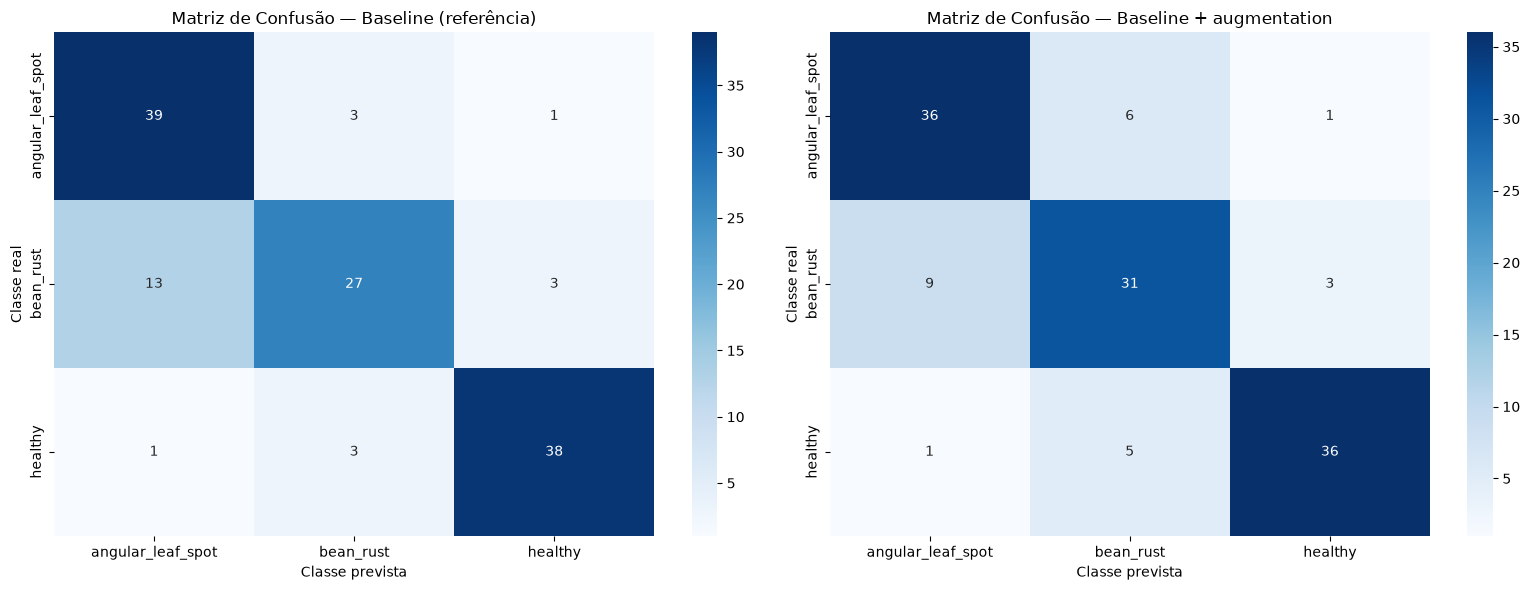

In [4]:
fig, axes = plt.subplots(1, len(predictions), figsize=(8 * len(predictions), 6))
axes = np.atleast_1d(axes)

for ax, (key, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_title(f"Matriz de Confusão — {condition_names[key]}")
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')

plt.tight_layout()
figures_dir = project_root / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(
    figures_dir / 'baseline_confusion_matrix.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

### 3.2 Interpretação dos resultados

No conjunto de **teste**, a condição de referência ficou ligeiramente à frente: acurácia **81,25%** e F1-macro **0,8093**, contra **80,47%** e **0,8055** com augmentation (diferença de ~1 imagem em 128). Na **validação**, contudo, o augmentation vence (**87,22%** vs **85,71%**), e é essa regra — definida no notebook 01 — que mantém o `baseline_aug` como modelo de referência das próximas etapas.

Por classe, o ganho mais claro do augmentation está em `bean_rust`: o recall sobe de **0,6279** para **0,7209** (27 → 31 acertos). Em troca, `angular_leaf_spot` cai de **0,9070** para **0,8372** e `healthy` de **0,9048** para **0,8571**. As matrizes de confusão confirmam o trade-off: a referência erra sobretudo `bean_rust` → `angular_leaf_spot` (13 casos); com augmentation esses erros caem para 9, mas aumentam os de `angular_leaf_spot` → `bean_rust` (3 → 6) e `healthy` → `bean_rust` (3 → 5).

Em resumo, o augmentation não eleva a acurácia/F1 de teste neste treino único, mas melhora o recall da classe mais difícil (`bean_rust`) e a validação — coerente com a EDA e com a escolha do modelo para Grad-CAM e Transfer Learning.

## 4. Conclusões e dificuldades

**Conclusões:**
- Treinamos do zero uma CNN pequena (23.779 parâmetros) em duas condições. A referência parou por early stopping na época 113 (melhor época 103, `val_loss` 0,3722); a condição com augmentation, na época 111 (melhor época 101, `val_loss` 0,3903). Nenhuma chegou ao teto de 200 épocas.
- Acurácia de validação e teste: **85,71%** e **81,25%** (referência); **87,22%** e **80,47%** (augmentation), muito acima do acaso (33%). F1-macro no teste: **0,8093** vs **0,8055**.
- Neste treino único o augmentation ganha na validação (+1,51 p.p.) e perde levemente no teste (−0,78 p.p., ≈ 1 imagem). O benefício mais claro é o recall de `bean_rust` (0,6279 → 0,7209). Não dá para atribuir o resultado só à augmentation: cada condição foi treinada uma vez.
- Pela regra do 01 (escolher pela validação), o **baseline + augmentation** segue como referência para Grad-CAM (notebook 04) e Transfer Learning (Entrega 2).

**Dificuldades:**
- **Quantidade de imagens:** o conjunto de teste possui apenas 128 imagens, o que limita a estabilidade das métricas. Cada imagem representa aproximadamente 0,78 ponto percentual da acurácia.
- **Confusão entre doenças:** a troca principal continua entre `angular_leaf_spot` e `bean_rust`.
- **Variação das imagens:** diferenças de iluminação, enquadramento e fundos podem influenciar as classificações.
- **Detalhamento das lesões:** o redimensionamento das imagens para 224 × 224 pixels pode prejudicar a identificação de lesões pequenas.
- **Generalização:** os resultados obtidos não garantem o mesmo desempenho em imagens de outras lavouras ou em diferentes condições de captura.